# Week 4 · Task 1.2 — Boundary-contrast-stratified results

**Hypothesis tested (H2):** SAM 3's masks degrade on low-contrast polyp boundaries. If H2 holds, SAM 3's *Boundary IoU* advantage over U-Net should be smaller (or negative) in the low-contrast tertile than in the high-contrast tertile.

**Definition (fixed and logged in `decisions.md` before any results were looked at; agreed with Sebastian, email of 20 Oct):**
1. Grayscale image and GT mask only. **No predictions are used to build the bins.**
2. Resolution normalisation: resize image and mask (aspect preserved) so every image has diagonal `TARGET_DIAG` px.
3. Sobel gradient magnitude (3x3) on the normalised grayscale image.
4. Band: all pixels within `BAND_RATIO` x diagonal (2 %) of the GT contour, inside and outside the polyp.
5. Primary score: mean gradient magnitude inside the band, one value per test image.
6. Bins: tertiles (low / medium / high) of the 200 test images.
7. Sensitivity check: |mean intensity inside band - mean intensity outside band|, binned the same way.

**Structure.** *Part A* builds the bins from image + GT only and saves them. *Part B* joins them with `per_image_results.csv`. Run Part B only after Part A's definition is committed.

In [1]:
from pathlib import Path
import math
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "results" / "week4"
OUT.mkdir(parents=True, exist_ok=True)

# ---- Definition: do not tune these after looking at results ----
TARGET_DIAG = 640               # px. ~ smallest test-image diagonal (641), so nothing is upscaled
BAND_RATIO = 0.02               # band half-width = 2 % of the normalised diagonal (same ratio as Boundary IoU)
ROBUSTNESS_DIAGS = [400, 900]   # sensitivity of the tertile assignment to TARGET_DIAG
HD95_CAP = None                 # px. Set once the exclude-vs-cap policy is agreed with Sebastian, then re-run Part B
LABELS = ["low", "medium", "high"]

## Part A — build the contrast bins (image + GT only)

In [2]:
test_ids = [l.strip() for l in open(ROOT / "data" / "splits" / "test.txt") if l.strip() and not l.startswith("#")]
assert len(test_ids) == 200 and len(set(test_ids)) == 200

def load_pair(image_id):
    img = cv2.imread(str(ROOT / "data" / "kvasir-seg" / "images" / f"{image_id}.jpg"), cv2.IMREAD_GRAYSCALE)
    msk = cv2.imread(str(ROOT / "data" / "kvasir-seg" / "masks" / f"{image_id}.jpg"), cv2.IMREAD_GRAYSCALE)
    assert img is not None and msk is not None and img.shape == msk.shape, image_id
    return img.astype(np.float32), (msk > 127).astype(np.uint8)

def normalise(img, msk, target_diag):
    """Resize (aspect preserved) so the diagonal equals target_diag."""
    h, w = img.shape
    s = target_diag / math.hypot(h, w)
    size = (max(1, round(w * s)), max(1, round(h * s)))
    interp = cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR
    img_n = cv2.resize(img, size, interpolation=interp)
    msk_n = (cv2.resize(msk * 255, size, interpolation=cv2.INTER_NEAREST) > 127).astype(np.uint8)
    return img_n, msk_n

def band_masks(msk, r):
    """Pixels within Euclidean distance r of the GT contour, split into inside / outside the polyp."""
    d_in = cv2.distanceTransform(msk, cv2.DIST_L2, 5)           # inside pixel -> distance to nearest background pixel
    d_out = cv2.distanceTransform(1 - msk, cv2.DIST_L2, 5)      # outside pixel -> distance to nearest polyp pixel
    return (msk == 1) & (d_in <= r), (msk == 0) & (d_out <= r)

def prepare(image_id, target_diag=TARGET_DIAG, band_ratio=BAND_RATIO):
    img, msk = load_pair(image_id)
    img_n, msk_n = normalise(img, msk, target_diag)
    r = max(1, round(band_ratio * target_diag))
    gx = cv2.Sobel(img_n, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img_n, cv2.CV_32F, 0, 1, ksize=3)
    grad = np.hypot(gx, gy)
    inside, outside = band_masks(msk_n, r)
    assert inside.any() and outside.any(), image_id
    return msk, img_n, msk_n, grad, inside, outside

def contrast_features(image_id, target_diag=TARGET_DIAG):
    msk, img_n, msk_n, grad, inside, outside = prepare(image_id, target_diag)
    band = inside | outside
    return {
        "image_id": image_id,
        "contrast_grad": float(grad[band].mean()),                                 # PRIMARY
        "contrast_dI": float(abs(img_n[inside].mean() - img_n[outside].mean())),   # sensitivity check
        "band_px": int(band.sum()),
        "gt_area_pct_native": float(100 * msk.mean()),                             # from the GT mask, not from results
    }

def tertile(s):
    return pd.qcut(s, 3, labels=LABELS)

def rank_corr(a, b):
    return a.rank().corr(b.rank())          # Spearman, without scipy

In [3]:
feat = pd.DataFrame([contrast_features(i) for i in test_ids])
feat["contrast_bin"] = tertile(feat["contrast_grad"])
feat["contrast_dI_bin"] = tertile(feat["contrast_dI"])
assert feat[["contrast_grad", "contrast_dI"]].notna().all().all()
assert feat["contrast_bin"].value_counts().min() >= 66

feat.to_csv(OUT / "contrast_per_image.csv", index=False)     # saved BEFORE any result metric is joined
print("tertile cutoffs (mean gradient in band):", feat["contrast_grad"].quantile([1/3, 2/3]).round(2).tolist())
print("images per bin:", feat["contrast_bin"].value_counts().reindex(LABELS).to_dict())
print("band size (px):", feat["band_px"].describe()[["min", "50%", "max"]].round(0).to_dict())

tertile cutoffs (mean gradient in band): [34.59, 45.9]
images per bin: {'low': 67, 'medium': 66, 'high': 67}
band size (px): {'min': 3133.0, '50%': 15602.0, 'max': 34112.0}


### Robustness of the definition (image + GT only)

In [4]:
rob = {}
for D in ROBUSTNESS_DIAGS:
    alt = pd.Series([contrast_features(i, target_diag=D)["contrast_grad"] for i in test_ids])
    rob[f"TARGET_DIAG={D} vs {TARGET_DIAG}"] = {
        "spearman": round(rank_corr(feat["contrast_grad"], alt), 3),
        "same_tertile_%": round(100 * (tertile(alt).astype(str).values == feat["contrast_bin"].astype(str).values).mean(), 1)}
rob["intensity-difference vs gradient"] = {
    "spearman": round(rank_corr(feat["contrast_grad"], feat["contrast_dI"]), 3),
    "same_tertile_%": round(100 * (feat["contrast_dI_bin"].astype(str).values == feat["contrast_bin"].astype(str).values).mean(), 1)}
display(pd.DataFrame(rob).T)

,spearman,same_tertile_%
TARGET_DIAG=400 vs 640,0.979,89.0
TARGET_DIAG=900 vs 640,0.993,95.0
intensity-difference vs gradient,0.363,43.0


### Is contrast confounded with polyp size? (cross-tab, image + GT only)

In [5]:
size_bin = pd.cut(feat["gt_area_pct_native"], [0, 5, 15, np.inf], labels=["small", "medium", "large"], right=False)
display(pd.crosstab(feat["contrast_bin"], size_bin))
print("Spearman(contrast, polyp area %):", round(rank_corr(feat["contrast_grad"], feat["gt_area_pct_native"]), 3))

gt_area_pct_native,small,medium,large
contrast_bin,,,
low,18,34,15
medium,12,28,26
high,9,19,39


Spearman(contrast, polyp area %): 0.312


### Visual check of the band (look at inputs, not results)

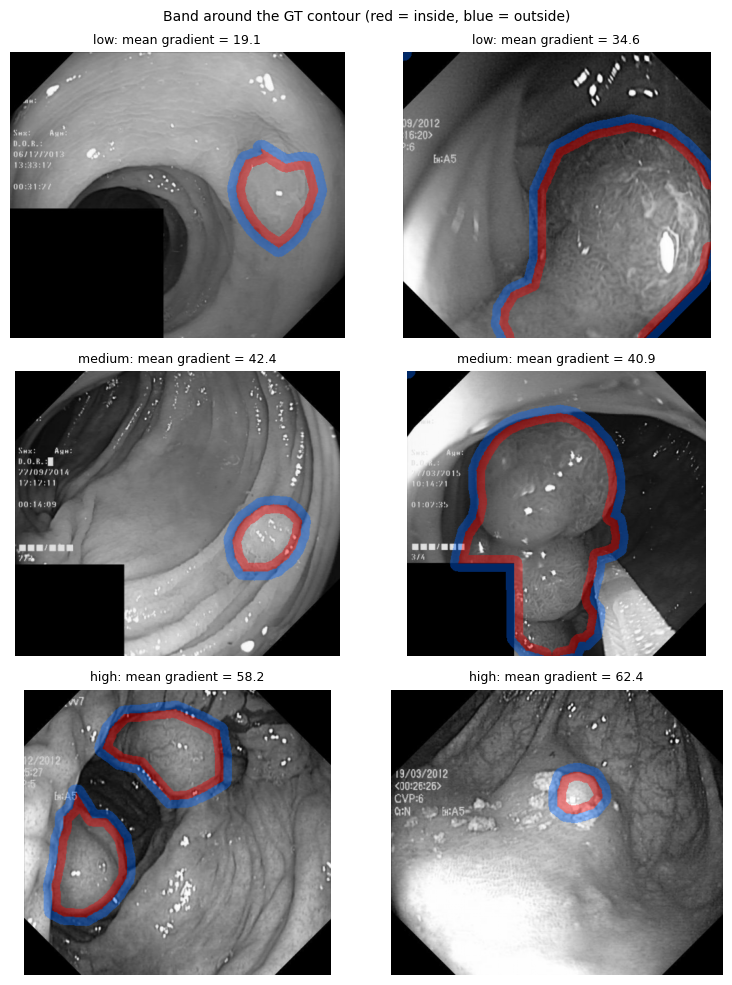

In [6]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(3, 2, figsize=(8, 10))
for row, lab in enumerate(LABELS):
    picks = rng.choice(feat.index[feat["contrast_bin"] == lab], size=2, replace=False)
    for col, k in enumerate(picks):
        iid = feat.loc[k, "image_id"]
        _, img_n, msk_n, grad, inside, outside = prepare(iid)
        rgb = np.repeat((img_n / 255.0)[..., None], 3, axis=-1)
        rgb[inside] = 0.6 * rgb[inside] + 0.4 * np.array([1.0, 0.0, 0.0])
        rgb[outside] = 0.6 * rgb[outside] + 0.4 * np.array([0.0, 0.4, 1.0])
        ax = axes[row, col]
        ax.imshow(np.clip(rgb, 0, 1)); ax.axis("off")
        ax.set_title(f"{lab}: mean gradient = {feat.loc[k, 'contrast_grad']:.1f}", fontsize=9)
fig.suptitle("Band around the GT contour (red = inside, blue = outside)", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "contrast_band_examples.png", dpi=110)
plt.show()

## Part B — join with the frozen results and stratify

Aggregation is the same as in notebook 07: mean over images within each run and bin, then mean ± std over seeds (U-Net) — **descriptive only; the significance tests (paired bootstrap + Wilcoxon) come from Sebastian's script.** HD95 uses the *exclude* policy here; set `HD95_CAP` in the config cell to also get the *cap* policy once agreed.

In [7]:
df = pd.read_csv(ROOT / "results" / "per_image_results.csv")
assert len(df) == 3400

cf = pd.read_csv(OUT / "contrast_per_image.csv")                 # bins fixed in Part A
for c in ["contrast_bin", "contrast_dI_bin"]:
    cf[c] = pd.Categorical(cf[c], LABELS, ordered=True)
df = df.merge(cf[["image_id", "contrast_bin", "contrast_dI_bin", "gt_area_pct_native"]],
              on="image_id", how="left", validate="many_to_one")
assert df["contrast_bin"].notna().all()

area_diff = (df["gt_area_pct"] - df["gt_area_pct_native"]).abs().max()
assert area_diff < 0.05, area_diff      # GT area computed from the masks must match the area in the results file
print(f"max |gt_area_pct (results) - gt_area_pct (masks)| = {area_diff:.4f} percentage points")

df["bracket"] = df["run_id"].str.extract(r"^(\d+)pct_seed\d+$")[0]
df["condition"] = np.where(df["arm"] == "unet", "unet-" + df["bracket"].fillna("") + "%", "sam3-" + df["run_id"])
ORDER = ["unet-10%", "unet-25%", "unet-50%", "unet-100%",
         "sam3-box-gt", "sam3-box-j10", "sam3-box-j20", "sam3-pt-1", "sam3-pt-3"]
assert set(df["condition"]) == set(ORDER)
UNETS = ORDER[:4]
HEADLINE_SAM3 = ["sam3-box-gt", "sam3-box-j10", "sam3-pt-3"]     # strategies named in the 20 Oct email
METRICS = ["dice", "iou", "boundary_iou", "hd95"]
n_bin = cf["contrast_bin"].value_counts().reindex(LABELS)

max |gt_area_pct (results) - gt_area_pct (masks)| = 0.0000 percentage points


In [8]:
def stratify(frame, bin_col, n_per_bin, hd95_policy="exclude"):
    """Mean over images within (run, bin), then mean and std over seeds.
    HD95 'exclude' drops non-finite rows; 'cap' replaces them by HD95_CAP."""
    f = frame.copy()
    inf = np.isinf(f["hd95"])
    if hd95_policy == "cap":
        assert HD95_CAP is not None, "set HD95_CAP first"
    f["hd95"] = f["hd95"].mask(inf, np.nan if hd95_policy == "exclude" else HD95_CAP)
    rm = f.groupby(["condition", "run_id", bin_col], observed=True)[METRICS].mean()
    s = rm.groupby(["condition", bin_col], observed=True).agg(["mean", "std"])
    s.columns = [f"{m}_{k}" for m, k in s.columns]
    s = s.reset_index()
    s["n_images"] = s[bin_col].astype(str).map(n_per_bin.to_dict()).astype(int)
    s["condition"] = pd.Categorical(s["condition"], ORDER, ordered=True)
    return rm, s.sort_values([bin_col, "condition"]).reset_index(drop=True)

def table(summary, bin_col, metric, digits=3):
    m = summary.pivot(index=bin_col, columns="condition", values=f"{metric}_mean")
    s = summary.pivot(index=bin_col, columns="condition", values=f"{metric}_std")
    fmt = lambda a, b: "n/a" if np.isnan(a) else (f"{a:.{digits}f}" if np.isnan(b) else f"{a:.{digits}f} ± {b:.{digits}f}")
    return pd.DataFrame({c: [fmt(m.loc[r, c], s.loc[r, c]) for r in LABELS] for c in ORDER}, index=LABELS)

def gap_table(summary, bin_col, metric, sam):
    """SAM 3 minus U-Net per bin. Dice/IoU/Boundary IoU: positive = SAM 3 ahead. HD95: NEGATIVE = SAM 3 ahead."""
    m = summary.pivot(index=bin_col, columns="condition", values=f"{metric}_mean")
    g = pd.DataFrame({u: m[sam] - m[u] for u in UNETS}).loc[LABELS]
    g.loc["high minus low"] = g.loc["high"] - g.loc["low"]
    return g

# HD95 exclusions (non-finite = empty prediction), counted per contrast bin
excl = (df[np.isinf(df["hd95"])].groupby(["condition", "contrast_bin"], observed=True).size()
          .unstack("contrast_bin").reindex(index=ORDER, columns=LABELS).fillna(0).astype(int))
excl.to_csv(OUT / "hd95_excluded_by_contrast_bin.csv")
assert excl.values.sum() == np.isinf(df["hd95"]).sum()
print("non-finite HD95 rows by condition x contrast bin:")
display(excl)

rm, summary = stratify(df, "contrast_bin", n_bin)
summary.to_csv(OUT / "contrast_stratified_summary.csv", index=False)

non-finite HD95 rows by condition x contrast bin:


contrast_bin,low,medium,high
condition,,,
unet-10%,3,0,0
unet-25%,2,0,0
unet-50%,4,3,0
unet-100%,4,3,0
sam3-box-gt,0,0,0
sam3-box-j10,0,0,0
sam3-box-j20,0,0,0
sam3-pt-1,0,0,0
sam3-pt-3,0,0,0


In [9]:
# sanity: the bin-weighted Dice must reproduce each run's overall Dice
by_bin = rm["dice"].unstack("contrast_bin")[LABELS]
weighted = by_bin.mul(n_bin[LABELS]).sum(axis=1) / n_bin.sum()
direct = df.groupby(["condition", "run_id"])["dice"].mean()
assert np.allclose(weighted.sort_index().values, direct.reindex(weighted.index).sort_index().values)
print("ok: bin-weighted Dice == overall Dice for all 17 runs")

ok: bin-weighted Dice == overall Dice for all 17 runs


### Primary tables (gradient-based contrast tertiles)

In [10]:
print("images per bin:", n_bin.to_dict(), "| seed std is descriptive only")
for metric in METRICS:
    print(f"\n=== {metric} ===" + ("  (non-finite rows excluded, see counts above)" if metric == "hd95" else ""))
    display(table(summary, "contrast_bin", metric, digits=1 if metric == "hd95" else 3))

images per bin: {'low': 67, 'medium': 66, 'high': 67} | seed std is descriptive only

=== dice ===


,unet-10%,unet-25%,unet-50%,unet-100%,sam3-box-gt,sam3-box-j10,sam3-box-j20,sam3-pt-1,sam3-pt-3
low,0.754 ± 0.017,0.803 ± 0.014,0.830 ± 0.016,0.846 ± 0.004,0.911,0.875,0.811,0.860,0.873
medium,0.777 ± 0.009,0.816 ± 0.013,0.837 ± 0.002,0.854 ± 0.005,0.883,0.849,0.734,0.793,0.854
high,0.773 ± 0.002,0.797 ± 0.013,0.821 ± 0.007,0.838 ± 0.008,0.889,0.813,0.687,0.806,0.868



=== iou ===


,unet-10%,unet-25%,unet-50%,unet-100%,sam3-box-gt,sam3-box-j10,sam3-box-j20,sam3-pt-1,sam3-pt-3
low,0.658 ± 0.022,0.717 ± 0.014,0.752 ± 0.017,0.773 ± 0.006,0.855,0.810,0.735,0.789,0.806
medium,0.673 ± 0.013,0.722 ± 0.019,0.753 ± 0.005,0.771 ± 0.008,0.825,0.781,0.651,0.720,0.779
high,0.669 ± 0.003,0.701 ± 0.019,0.729 ± 0.009,0.752 ± 0.007,0.830,0.749,0.595,0.727,0.793



=== boundary_iou ===


,unet-10%,unet-25%,unet-50%,unet-100%,sam3-box-gt,sam3-box-j10,sam3-box-j20,sam3-pt-1,sam3-pt-3
low,0.428 ± 0.015,0.482 ± 0.012,0.516 ± 0.014,0.539 ± 0.008,0.633,0.567,0.489,0.562,0.561
medium,0.415 ± 0.011,0.457 ± 0.018,0.501 ± 0.007,0.507 ± 0.010,0.570,0.497,0.381,0.473,0.518
high,0.387 ± 0.005,0.426 ± 0.024,0.465 ± 0.010,0.473 ± 0.009,0.561,0.474,0.351,0.454,0.498



=== hd95 ===  (non-finite rows excluded, see counts above)


,unet-10%,unet-25%,unet-50%,unet-100%,sam3-box-gt,sam3-box-j10,sam3-box-j20,sam3-pt-1,sam3-pt-3
low,110.0 ± 0.9,83.0 ± 5.7,83.9 ± 8.9,71.6 ± 3.8,27.3,33.0,38.6,52.3,48.7
medium,101.2 ± 0.6,82.6 ± 5.4,77.7 ± 3.2,62.5 ± 1.5,33.7,37.5,58.4,65.0,51.9
high,109.6 ± 10.1,102.5 ± 5.7,92.3 ± 3.0,79.6 ± 5.7,43.0,43.5,63.4,67.5,54.1


### SAM 3 minus U-Net, by contrast tertile (H2 reads off the Boundary IoU rows)

In [11]:
for metric in ["boundary_iou", "dice"]:
    for sam in HEADLINE_SAM3:
        print(f"\n=== {metric}: {sam} minus U-Net  (+ = SAM 3 ahead) ===")
        display(gap_table(summary, "contrast_bin", metric, sam).round(3))


=== boundary_iou: sam3-box-gt minus U-Net  (+ = SAM 3 ahead) ===


,unet-10%,unet-25%,unet-50%,unet-100%
contrast_bin,,,,
low,0.205,0.151,0.117,0.094
medium,0.155,0.112,0.069,0.063
high,0.174,0.134,0.096,0.088
high minus low,-0.031,-0.017,-0.022,-0.006



=== boundary_iou: sam3-box-j10 minus U-Net  (+ = SAM 3 ahead) ===


,unet-10%,unet-25%,unet-50%,unet-100%
contrast_bin,,,,
low,0.139,0.085,0.051,0.027
medium,0.082,0.039,-0.004,-0.010
high,0.087,0.048,0.009,0.002
high minus low,-0.051,-0.037,-0.042,-0.026



=== boundary_iou: sam3-pt-3 minus U-Net  (+ = SAM 3 ahead) ===


...

,unet-10%,unet-25%,unet-50%,unet-100%
contrast_bin,,,,
low,0.157,0.107,0.081,0.065
medium,0.105,0.066,0.045,0.029
high,0.116,0.093,0.068,0.052
high minus low,-0.041,-0.015,-0.013,-0.013



=== dice: sam3-box-j10 minus U-Net  (+ = SAM 3 ahead) ===


,unet-10%,unet-25%,unet-50%,unet-100%
contrast_bin,,,,
low,0.121,0.072,0.045,0.029
medium,0.072,0.033,0.012,-0.004
high,0.040,0.017,-0.008,-0.024
high minus low,-0.081,-0.055,-0.053,-0.053



=== dice: sam3-pt-3 minus U-Net  (+ = SAM 3 ahead) ===


,unet-10%,unet-25%,unet-50%,unet-100%
contrast_bin,,,,
low,0.119,0.070,0.043,0.027
medium,0.077,0.038,0.017,0.000
high,0.095,0.072,0.047,0.031
high minus low,-0.024,0.002,0.004,0.003


### HD95 with the cap policy (runs once `HD95_CAP` is set)

In [12]:
if HD95_CAP is None:
    print("HD95_CAP not set; skipping the cap version.")
else:
    _, summary_cap = stratify(df, "contrast_bin", n_bin, hd95_policy="cap")
    summary_cap.to_csv(OUT / "contrast_stratified_summary_hd95cap.csv", index=False)
    display(table(summary_cap, "contrast_bin", "hd95", digits=1))

HD95_CAP not set; skipping the cap version.


### Sensitivity: intensity-difference bins instead of gradient bins

In [13]:
n_bin_dI = cf["contrast_dI_bin"].value_counts().reindex(LABELS)      # tertile sizes can differ by 1
rm2, summary2 = stratify(df, "contrast_dI_bin", n_bin_dI)
summary2.to_csv(OUT / "contrast_dI_stratified_summary.csv", index=False)
for sam in HEADLINE_SAM3:
    print(f"\n=== boundary_iou, intensity-difference tertiles: {sam} minus U-Net ===")
    display(gap_table(summary2, "contrast_dI_bin", "boundary_iou", sam).round(3))


=== boundary_iou, intensity-difference tertiles: sam3-box-gt minus U-Net ===


,unet-10%,unet-25%,unet-50%,unet-100%
contrast_dI_bin,,,,
low,0.231,0.169,0.139,0.110
medium,0.127,0.109,0.057,0.042
high,0.174,0.120,0.086,0.093
high minus low,-0.056,-0.049,-0.053,-0.017



=== boundary_iou, intensity-difference tertiles: sam3-box-j10 minus U-Net ===


,unet-10%,unet-25%,unet-50%,unet-100%
contrast_dI_bin,,,,
low,0.157,0.095,0.065,0.036
medium,0.044,0.026,-0.026,-0.041
high,0.106,0.051,0.018,0.024
high minus low,-0.051,-0.044,-0.047,-0.012



=== boundary_iou, intensity-difference tertiles: sam3-pt-3 minus U-Net ===


,unet-10%,unet-25%,unet-50%,unet-100%
contrast_dI_bin,,,,
low,0.121,0.059,0.029,-0.001
medium,0.083,0.065,0.013,-0.002
high,0.144,0.089,0.055,0.062
high minus low,0.023,0.030,0.027,0.062


## Reading the output
- Everything here is descriptive. Paired bootstrap CIs and Wilcoxon tests per bin come from Sebastian's stats script (size-bin option; a contrast-bin option is needed too).
- Each bin has about 67 images; the within-bin comparisons are noisy. Say so in the report.
- Name the SAM 3 strategy in every statement. The `box-gt` prompt is an oracle.
- Check the size cross-tab above before attributing an effect to contrast rather than to polyp size.
- HD95: quote the exclusion counts next to every HD95 number.